# Sensitivity Analysis on EIM Sensors for Parametric State Estimation with Shallow Decoder Network on TRIGA-MC data
This notebook implements a Sensitivity Analysis for Shallow Decoder Network (SDN) aimed at reconstructing the state (the total flux $\Phi$) of a TRIGA reactor based on its operational parameters (position of the SHIM and REG control rod) and few local measurements collected at EIM positions.

This notebook will investigate:
1. the influence of the number of sensors on the reconstruction of the state vector either with or without the operational parameters (including the case with no sensors);

For the following discussion, let $\mathbf{f}$ be the SDN model, $\mathbf{y}$ the input measures, $\boldsymbol{\mu}$ the parameters and $\mathbf{u}$ the output state of the reactor, let $\mathbf{v}$ be the low-dimensional representation of the state vector $\mathbf{u}$, obtained by projecting the high-dimensional flux data on the SVD modes, and let $\mathbb{U}$ be the matrix of SVD modes.

This notebook can load MonteCarlo data either with low or high statistics (the uncertainty is higher for low statistics, two times higher).

In [ ]:
from matplotlib import rcParams
from matplotlib import cm
import seaborn as sns
# rcParams.update({
#   "text.usetex": True,
#   "font.family": "serif"
# })

# rcParams['text.latex.preamble'] = r'\usepackage{amssymb} \usepackage{amsmath} \usepackage{amsthm} \usepackage{mathtools}'

import os
path_res = os.path.join(os.getcwd(), 'Results/SensitivityAnalysis/SensorsEIM/')
os.makedirs(path_res, exist_ok=True)

Let us import the data

In [2]:
# _stats = '_lowstats'
_stats = '_highstats'

import numpy as np
_tmp = np.load(f'Data/flux_data{_stats}.npz', allow_pickle=True)

snaps = _tmp['flux']
params = _tmp['params']
centroids = _tmp['centroids']

del _tmp

Let us separate the data into a training and test set, the seed is set to 42 for reproducibility.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

train_indices, test_indices, train_params, test_params = train_test_split(np.arange(len(params)), params, test_size=0.2, random_state=42)

valid_indices = test_indices[::2]
test_indices = test_indices[1::2]

valid_params = test_params[::2]
test_params = test_params[1::2]

max_flux = snaps[:, train_indices].max()
train_data = snaps[:, train_indices] / max_flux
test_data  = snaps[:, test_indices] / max_flux
valid_data = snaps[:, valid_indices] / max_flux

print(train_data.shape, test_data.shape, valid_data.shape)

(126750, 96) (126750, 12) (126750, 13)


Let us perform the SVD on the snaps matrix

In [4]:
from sklearn.decomposition import randomized_svd

modes, sing_vals, _ = randomized_svd(train_data, n_components=50, n_iter='auto')

rank = 5
train_pod_coeffs = np.dot(modes[:,:rank].T, train_data)
test_pod_coeffs  = np.dot(modes[:,:rank].T, test_data)
valid_pod_coeffs = np.dot(modes[:,:rank].T, valid_data)


_test_pod = np.dot(modes[:,:rank].T, test_data)
_test_rec = np.dot(modes[:,:rank], _test_pod)
print(f"Relative error for rank {rank}: {np.linalg.norm(_test_rec - test_data) / np.linalg.norm(test_data):.4e}")

Relative error for rank 5: 1.2382e-02


Let us set the device onto which the model will be loaded, either CPU or GPU or MPS.

In [ ]:
import torch
from utils.sdn import ShallowDecoderNetwork, MyDataset, fit

# Set the device
device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')

compressive_training = True

Let us define the error dictionary

In [6]:
errors = dict()
num_senss = np.concatenate([[1,2,3,4,5], np.arange(10, 41, 10)]) # Not testing all numbers, just a few

## Empirical Interpolation Method (EIM)
The Empirical Interpolation Method (EIM) is a technique used to place sensors within the domain of the reactor.

In [7]:
from utils.eim import EIM

eeim = EIM(centroids, name='flux')

eeim.offline(train_data, 40, verbose=True)
print(f"Offline EIM done!")

Offline EIM done! Abs Err: 2.04e-02 | Rel Err: 2.38e-02


Let us calculate the test error

In [8]:
errors['EIM'] = np.zeros((len(num_senss), *test_data.T.shape))

for ii, mm in enumerate(num_senss):
    print(f"Running EIM Online for {mm} sensors")

    beta_coeffs = np.array([eeim.reconstruct(test_data[:, mu], mm)[0] for mu in range(test_data.shape[1])]).T
    _eim_rec = np.dot(eeim.magic_fun[:, :mm], beta_coeffs)

    errors['EIM'][ii] = np.abs(_eim_rec.T - test_data.T)

Running EIM Online for 1 sensors
Running EIM Online for 2 sensors
Running EIM Online for 3 sensors
Running EIM Online for 4 sensors
Running EIM Online for 5 sensors
Running EIM Online for 10 sensors
Running EIM Online for 20 sensors
Running EIM Online for 30 sensors
Running EIM Online for 40 sensors


## Influence of the number of sensors and their positions
At first, we will investigate the influence of the number of sensors on the reconstruction of the state vector, the influence of the position will be investigated by performing different repetead numerical experiments with different seed number. 

Let $\mathbf{y}_M$ be the vector of $M$ measurements and let us indicate with $\mathbf{f}_M$ the SDN model trained with $M$ measurements whose output is $\mathbf{u}_M = \mathbb{U}\mathbf{f}_M(\mathbf{y}_M, \boldsymbol{\mu})$.

### Including the operational parameters
In this cell, the sensitivity analysis on the number of sensors is performed including the operational parameters (the position of the SHIM and REG control rod).

The output will be the error between the reconstructed state vector $\mathbf{u}_M$ and the ground truth state vector $\mathbf{u}$.

In [9]:
from IPython.display import clear_output as clc

def run_sensitivity_analysis_with_params(mm, random_seed: int = None):

    if random_seed is not None:
        print(f'Running sensitivity analysis with {mm} random sensors including parameters - Random Seed: {random_seed}')
    else:
        print(f'Running sensitivity analysis with {mm} EIM sensors including parameters')

    if mm == 0:
        # Create the input data for the SDN
        train_input = params[train_indices].T
        test_input  = params[test_indices].T
        valid_input = params[valid_indices].T
    else:
        if random_seed is not None:
            np.random.seed(random_seed)  # For reproducibility
            idx_sens_locs = np.random.choice(train_data.shape[0], size=mm, replace=False)
        else:
            idx_sens_locs = eeim.magic_points['idx'][:mm]  # Get the sensor locations from EIM

        # Create the input data for the SDN
        train_input = np.concatenate([train_data[idx_sens_locs], params[train_indices].T], axis=0)
        test_input  = np.concatenate([test_data[idx_sens_locs], params[test_indices].T], axis=0)
        valid_input = np.concatenate([valid_data[idx_sens_locs], params[valid_indices].T], axis=0)

    # Define the scaler for the input data
    input_scaler = MinMaxScaler()
    input_scaler.fit(train_input.T)

    # Scale the input data
    train_input = input_scaler.transform(train_input.T).T
    test_input  = input_scaler.transform(test_input.T).T
    valid_input = input_scaler.transform(valid_input.T).T

    # Define the dataset for input and output
    train_dataset = MyDataset(torch.tensor(train_input.T, dtype=torch.float32).to(device), torch.tensor(train_data.T, dtype=torch.float32).to(device))
    test_dataset  = MyDataset(torch.tensor(test_input.T, dtype=torch.float32).to(device),  torch.tensor(test_data.T, dtype=torch.float32).to(device))
    valid_dataset = MyDataset(torch.tensor(valid_input.T, dtype=torch.float32).to(device), torch.tensor(valid_data.T, dtype=torch.float32).to(device))

    # Define the SDN model
    in_dim = train_input.shape[0]
    out_dim = rank if compressive_training else train_data.shape[0]
    pod_modes = torch.tensor(modes[:, :rank], dtype=torch.float32).to(device) if compressive_training else None

    sdn = ShallowDecoderNetwork(in_dim = in_dim, out_dim=out_dim, dropout=0.1, decoder_sizes=[350,400], pod_modes=pod_modes).to(device)

    fit(model=sdn, train_dataset=train_dataset, valid_dataset=valid_dataset, 
        batch_size=32, epochs=500, patience=30,
        optim=torch.optim.Adam, criterion=torch.nn.L1Loss(), lr=0.001, 
        verbose=True)
    
    # Evaluate the model
    sdn.freeze()

    clc()

    # return np.linalg.norm(sdn(test_dataset.X).cpu().detach().numpy() - test_data.T) / np.linalg.norm(test_data.T) 
    return np.abs(sdn(test_dataset.X).cpu().detach().numpy() - test_data.T)

errors['NumSensEIM_WithParam']    = np.array([run_sensitivity_analysis_with_params(mm) for mm in num_senss])

_tmp = []
for random_seed in range(0, 31, 2):
    _tmp.append([run_sensitivity_analysis_with_params(mm, random_seed=random_seed) for mm in num_senss])
errors['NumSensRandom_WithParam'] = {
    'mean': np.array(_tmp).mean(axis=0),
    'std': np.array(_tmp).std(axis=0)
}

del _tmp

### Excluding the operational parameters
In this cell, the sensitivity analysis on the number of sensors is performed without the operational parameters (the position of the SHIM and REG control rod).

The output will be the error between the reconstructed state vector $\mathbf{u}_M$ and the ground truth state vector $\mathbf{u}$.

In [10]:
from IPython.display import clear_output as clc

def run_sensitivity_analysis_no_params(mm, random_seed: int = None):

    if random_seed is not None:
        print(f'Running sensitivity analysis with {mm} random sensors without parameters - Random Seed: {random_seed}')
    else:
        print(f'Running sensitivity analysis with {mm} EIM sensors without parameters')

    if random_seed is not None:
        np.random.seed(random_seed)  # For reproducibility
        idx_sens_locs = np.random.choice(train_data.shape[0], size=mm, replace=False)
    else:
        idx_sens_locs = eeim.magic_points['idx'][:mm]  # Get the sensor locations from EIM

    # Create the input data for the SDN
    train_input = train_data[idx_sens_locs]
    test_input  = test_data[idx_sens_locs]
    valid_input = valid_data[idx_sens_locs]

    # Define the scaler for the input data
    input_scaler = MinMaxScaler()
    input_scaler.fit(train_input.T)

    # Scale the input data
    train_input = input_scaler.transform(train_input.T).T
    test_input  = input_scaler.transform(test_input.T).T
    valid_input = input_scaler.transform(valid_input.T).T

    # Define the dataset for input and output
    train_dataset = MyDataset(torch.tensor(train_input.T, dtype=torch.float32).to(device), torch.tensor(train_data.T, dtype=torch.float32).to(device))
    test_dataset  = MyDataset(torch.tensor(test_input.T, dtype=torch.float32).to(device),  torch.tensor(test_data.T, dtype=torch.float32).to(device))
    valid_dataset = MyDataset(torch.tensor(valid_input.T, dtype=torch.float32).to(device), torch.tensor(valid_data.T, dtype=torch.float32).to(device))

    # Define the SDN model
    in_dim = train_input.shape[0]
    out_dim = rank if compressive_training else train_data.shape[0]
    pod_modes = torch.tensor(modes[:, :rank], dtype=torch.float32).to(device) if compressive_training else None

    sdn = ShallowDecoderNetwork(in_dim = in_dim, out_dim=out_dim, dropout=0.1, decoder_sizes=[350,400], pod_modes=pod_modes).to(device)

    fit(model=sdn, train_dataset=train_dataset, valid_dataset=valid_dataset, 
        batch_size=32, epochs=500, patience=30,
        optim=torch.optim.Adam, criterion=torch.nn.L1Loss(), lr=0.001, 
        verbose=True)
    
    # Evaluate the model
    sdn.freeze()
    
    clc()

    # return np.linalg.norm(sdn(test_dataset.X).cpu().detach().numpy() - test_data.T) / np.linalg.norm(test_data.T) 
    return np.abs(sdn(test_dataset.X).cpu().detach().numpy() - test_data.T) 

errors['NumSensEIM_WithoutParam']    = np.array([run_sensitivity_analysis_no_params(mm) for mm in num_senss])

_tmp = []
for random_seed in range(0, 31, 2):
    _tmp.append([run_sensitivity_analysis_no_params(mm, random_seed=random_seed) for mm in num_senss])
errors['NumSensRandom_WithoutParam'] = {
    'mean': np.array(_tmp).mean(axis=0),
    'std': np.array(_tmp).std(axis=0)
}
del _tmp

### Comparison of the results
Let us compare the results of the sensitivity analysis with and without the operational parameters. 

At first, let us store the residual fields in `npz` files.

In [11]:
import os

np.savez_compressed(path_res + f'/sensitivity_analysis{_stats}.npz',
                   errors=errors,
                   num_senss=eeim.magic_points['idx'])

errors = np.load(path_res + f'/sensitivity_analysis{_stats}.npz', allow_pickle=True)
errors = errors['errors'].item()

Since different numerical experiments are performed we can compute the mean and standard deviation of the errors.

Let $\hat{\mathbf{u}}_M(\boldsymbol{\mu})$ be the reconstructed state vector with $M$ sensors and operational parameters $\boldsymbol{\mu}$, we can compute the average relative error as follows:
$$ 
\varepsilon_M = \frac{1}{N_s^{test}} \sum_{i=1}^{N_s^{test}} \frac{\| \hat{\mathbf{u}}_M(\boldsymbol{\mu}_i) - \mathbf{u}(\boldsymbol{\mu}_i)\|_2}{\| \mathbf{u}(\boldsymbol{\mu}_i)\|_2}
$$
where $N_s^{test}$ is the number of test parameters.

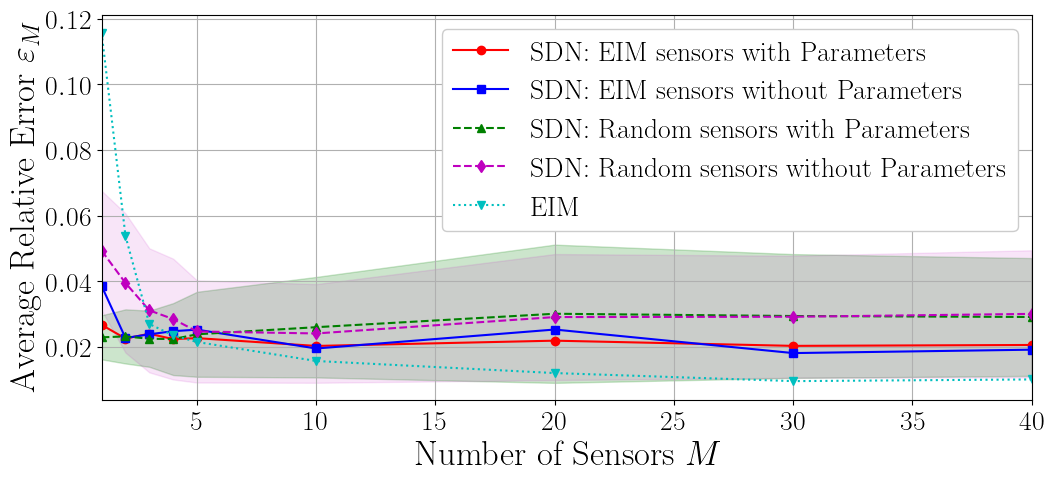

In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))

# SDN -> EIM + Parameters
mean_eim_with = (np.linalg.norm(errors['NumSensEIM_WithParam'], axis=-1) / np.linalg.norm(test_data, axis=0)).mean(axis=-1)
mean_eim_without = (np.linalg.norm(errors['NumSensEIM_WithoutParam'], axis=-1) / np.linalg.norm(test_data, axis=0)).mean(axis=-1)

# SDN -> Random + Parameters
mean_random_with = {
    'mean': (np.linalg.norm(errors['NumSensRandom_WithParam']['mean'], axis=-1) / np.linalg.norm(test_data, axis=0)).mean(axis=-1),
    'std': (np.linalg.norm(errors['NumSensRandom_WithParam']['std'], axis=-1) / np.linalg.norm(test_data, axis=0)).mean(axis=-1)
}
mean_random_without = {
    'mean': (np.linalg.norm(errors['NumSensRandom_WithoutParam']['mean'], axis=-1) / np.linalg.norm(test_data, axis=0)).mean(axis=-1),
    'std': (np.linalg.norm(errors['NumSensRandom_WithoutParam']['std'], axis=-1) / np.linalg.norm(test_data, axis=0)).mean(axis=-1)
}

# EIM
mean_eim = (np.linalg.norm(errors['EIM'], axis=-1) / np.linalg.norm(test_data, axis=0)).mean(axis=-1)

ax.plot(num_senss, mean_eim_with, color='r', marker='o', label='SDN: EIM sensors with Parameters')
ax.plot(num_senss, mean_eim_without, color='b', marker='s', label='SDN: EIM sensors without Parameters')

## Plots
ax.plot(num_senss, mean_random_with['mean'], '--', color='g', marker='^', label='SDN: Random sensors with Parameters')
ax.fill_between(num_senss, mean_random_with['mean'] - mean_random_with['std'], mean_random_with['mean'] + mean_random_with['std'], color='g', alpha=0.2)

ax.plot(num_senss, mean_random_without['mean'], '--', color='m', marker='d', label='SDN: Random sensors without Parameters')
ax.fill_between(num_senss, mean_random_without['mean'] - mean_random_without['std'], mean_random_without['mean'] + mean_random_without['std'], color='m', alpha=0.1)

ax.plot(num_senss, mean_eim, ':', color='c', marker='v', label='EIM')

ax.set_xlabel('Number of Sensors $M$', fontsize=25)
ax.set_ylabel(r'Average Relative Error $ \varepsilon_M$', fontsize=25)
ax.legend(framealpha=1, ncols=1, fontsize=20, loc='upper right')
ax.grid()
ax.set_xlim(1, num_senss[-1])
ax.tick_params(axis='both', which='major', labelsize=20)
fig.savefig(path_res + f'/ave_rel_err_sensitivity{_stats}.pdf', bbox_inches='tight', dpi=300)


Let us observe how the residual field, defined as $\mathbf{r}_M = |\mathbf{u} - \mathbf{u}_M|$, is spread over the core adopting a statistical approach.

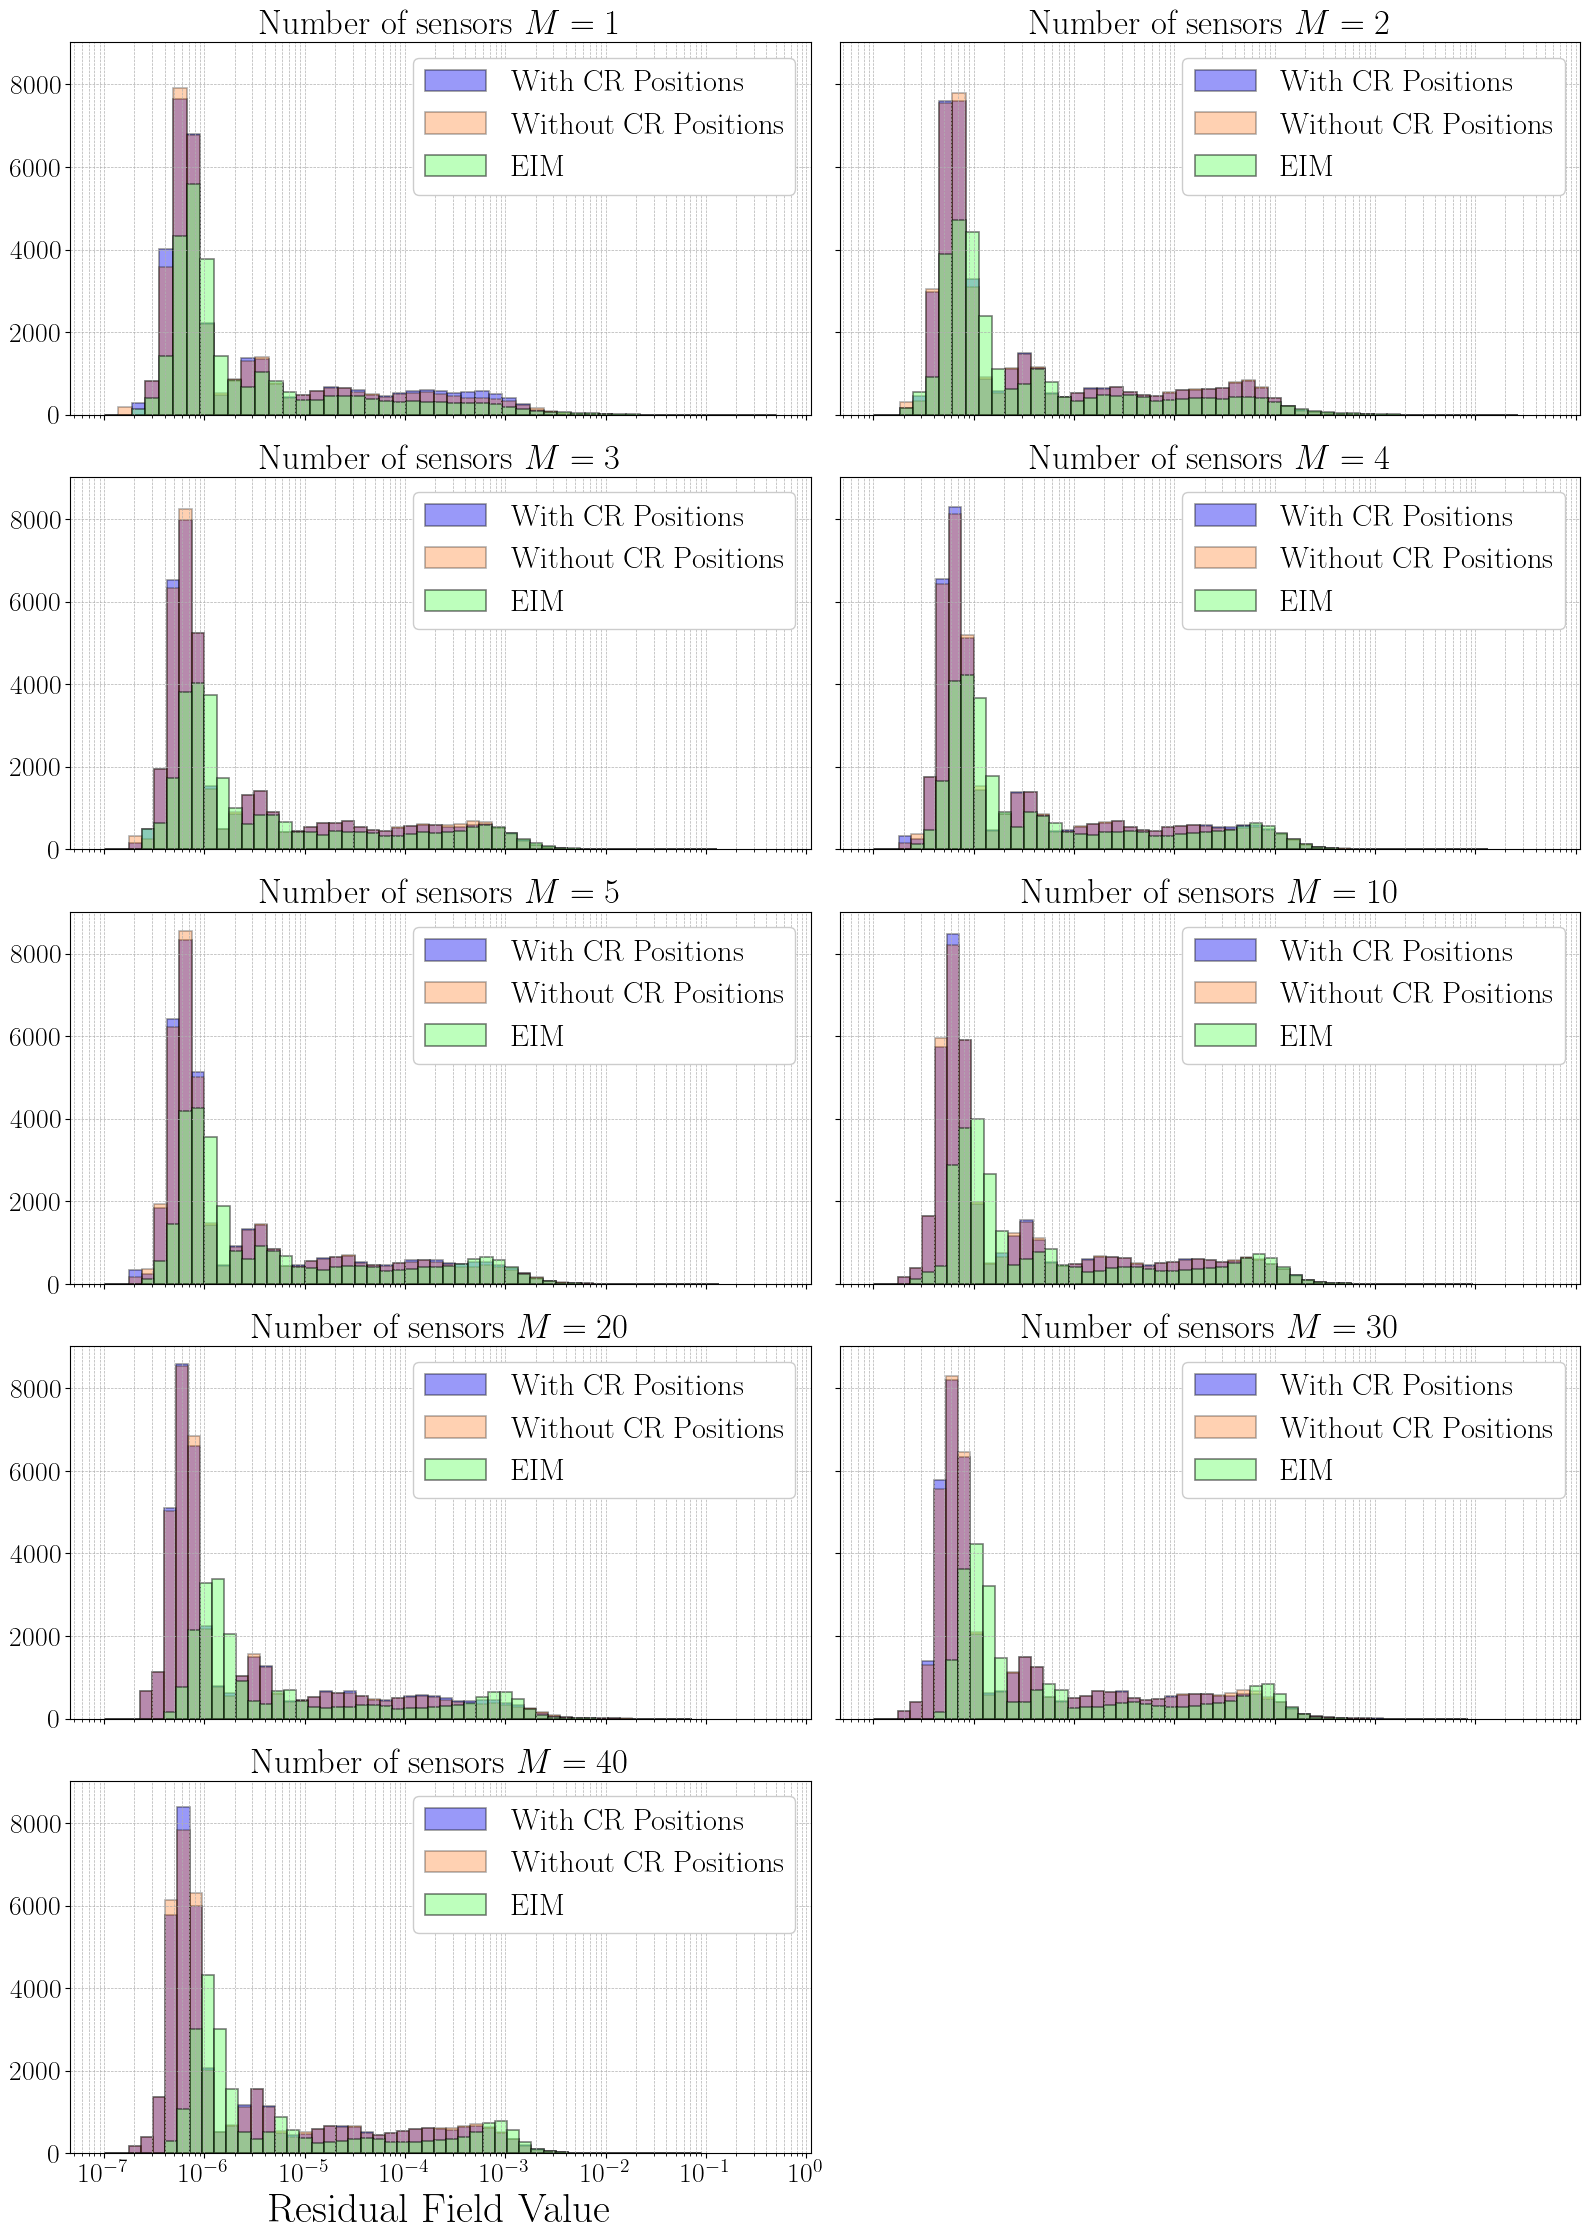

In [20]:
residuals_with_per_condition = [errors['NumSensEIM_WithParam'].mean(axis=1)[i, :] for i in range(len(num_senss))]
residuals_without_per_condition = [errors['NumSensEIM_WithoutParam'].mean(axis=1)[i, :] for i in range(len(num_senss)-1)]
residuals_eim = [errors['EIM'].mean(axis=1)[i, :] for i in range(len(num_senss))]

ncols = 2
nrows = 5
fig, axes = plt.subplots(nrows, ncols, figsize=(8 * ncols, 4.5 * nrows), sharey=True, sharex=True)
axes = axes.flatten()

nbins = 50

for i in range(len(residuals_with_per_condition)):
    ax = axes[i]

    data = errors['NumSensEIM_WithParam'].mean(axis=1)[i, :]
    data_without = errors['NumSensEIM_WithoutParam'].mean(axis=1)[i, :]
    data_eim = errors['EIM'].mean(axis=1)[i, :]
    bins = np.logspace(-7, np.log10(max(data.max(), data_without.max(), data_eim.max())), nbins)
    ax.hist(data, bins=bins, color=cm.jet(0.1), alpha=0.4, edgecolor='black', linewidth=1.2, density=True, label='With CR Positions')
    ax.hist(data_without, bins=bins, color=cm.jet(0.8), alpha=0.3, edgecolor='black', linewidth=1.2, density=True, label='Without CR Positions')
    ax.hist(data_eim, bins=bins, color=cm.jet(0.5), alpha=0.5, edgecolor='black', linewidth=1.2, density=True, label='EIM')

    ax.set_xscale('log')
    ax.set_title('Number of sensors $M='+str(num_senss[i])+'$', fontsize=25)
    ax.grid(which='both', linestyle='--', linewidth=0.5)
    ax.tick_params(axis='both', which='major', labelsize=20)
    ax.legend(framealpha=1, ncols=1, fontsize=22, loc='upper right')
    
    if i >= (ncols * (nrows - 1)):
        ax.set_xlabel('Residual Field Value', fontsize=30)

for i in range(len(residuals_with_per_condition), len(axes)):
    axes[i].axis('off')  # Hide unused subplots

plt.tight_layout()

# _line, _labels = axes[1].get_legend_handles_labels()
# axes[-1].legend(_line, _labels, framealpha=1, ncols=1, fontsize=18, loc='upper left')

fig.savefig(path_res + f'/residual_hist{_stats}.pdf', bbox_inches='tight', dpi=300)

Let us make histograms for the paper

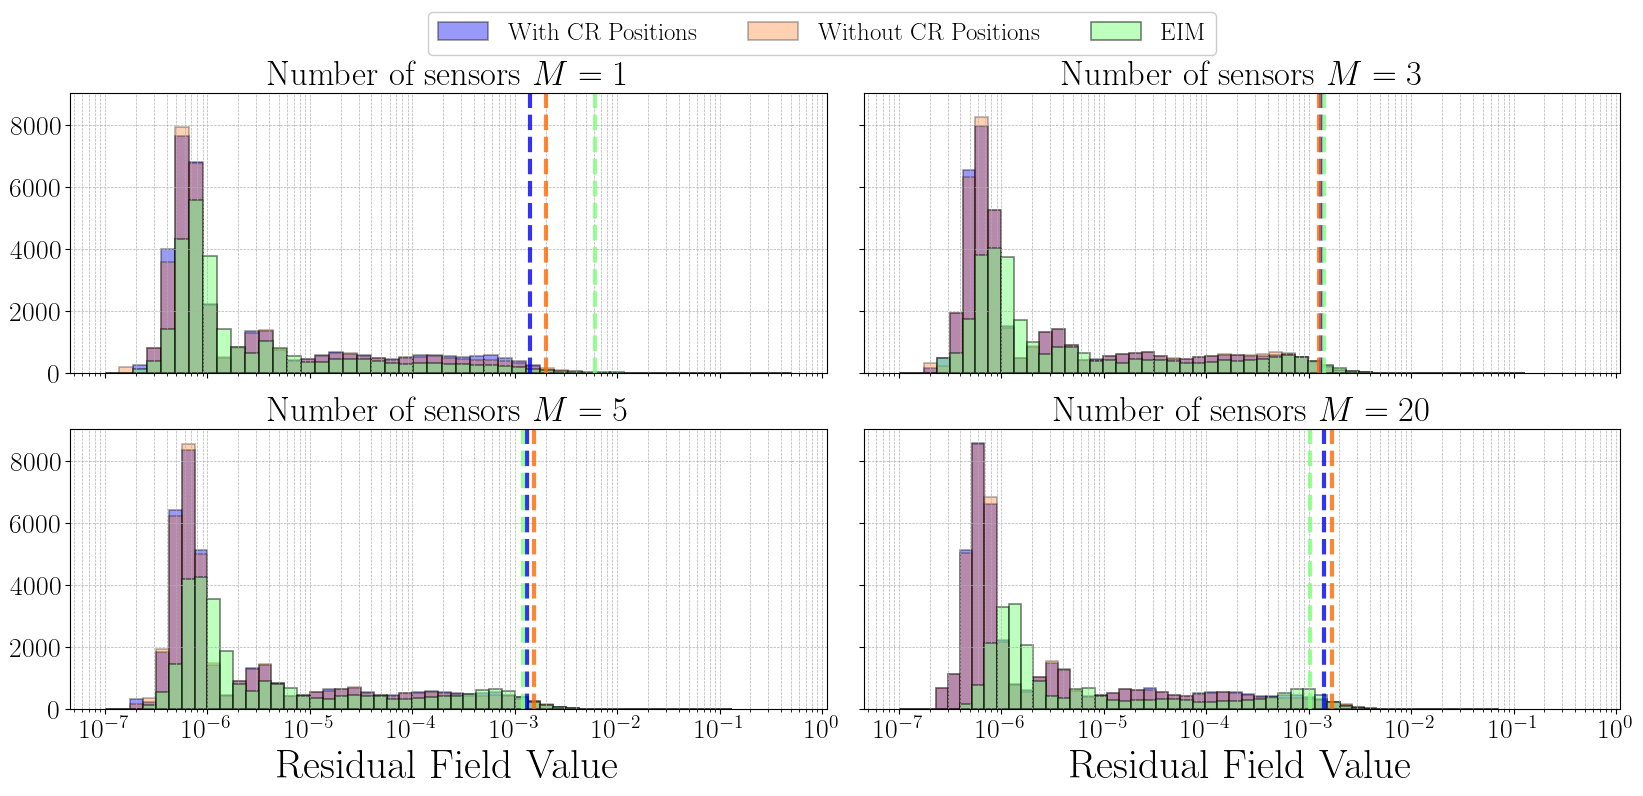

In [18]:
sens_to_plot = [0, 2, 4, 6]  # Indices of num_senss to plot

ncols = 2
nrows = 2

fig, axes = plt.subplots(nrows, ncols, figsize=(10 * ncols, 4 * nrows), sharey=True, sharex=True)
axes = axes.flatten()

nbins = 50

for i, sens_i in enumerate(sens_to_plot):
    ax = axes[i]

    data = errors['NumSensEIM_WithParam'].mean(axis=1)[sens_i, :]
    data_without = errors['NumSensEIM_WithoutParam'].mean(axis=1)[sens_i, :]
    data_eim = errors['EIM'].mean(axis=1)[sens_i, :]

    bins = np.logspace(-7, np.log10(max(data.max(), data_without.max(), data_eim.max())), nbins)

    # Histograms
    ax.hist(data, bins=bins, color=cm.jet(0.1), alpha=0.4, edgecolor='black', linewidth=1.2, density=True, label='With CR Positions')
    ax.hist(data_without, bins=bins, color=cm.jet(0.8), alpha=0.3, edgecolor='black', linewidth=1.2, density=True, label='Without CR Positions')
    ax.hist(data_eim, bins=bins, color=cm.jet(0.5), alpha=0.5, edgecolor='black', linewidth=1.2, density=True, label='EIM')

    # Add vertical lines for means
    ax.axvline(data.mean(), color=cm.jet(0.1), linestyle='--', linewidth=3, alpha=0.8)
    ax.axvline(data_without.mean(), color=cm.jet(0.8), linestyle='--', linewidth=3, alpha=0.8)
    ax.axvline(data_eim.mean(), color=cm.jet(0.5), linestyle='--', linewidth=3, alpha=0.8)

    ax.set_xscale('log')
    ax.set_title(f'Number of sensors $M={num_senss[sens_i]}$', fontsize=25)
    ax.grid(which='both', linestyle='--', linewidth=0.5)
    ax.tick_params(axis='both', which='major', labelsize=20)
    
    if i >= (ncols * (nrows - 1)):
        ax.set_xlabel('Residual Field Value', fontsize=30)

_line, _labels = axes[1].get_legend_handles_labels()
fig.legend(_line, _labels, framealpha=1, ncols=3, fontsize=18, loc='upper center')

fig.subplots_adjust(wspace=0.05)

fig.savefig(path_res + f'/immy_sensitivityeim_residual_hist{_stats}.pdf', bbox_inches='tight', dpi=300)

Let us make a violin plot of the residual field for each number of sensors, with and without operational parameters.

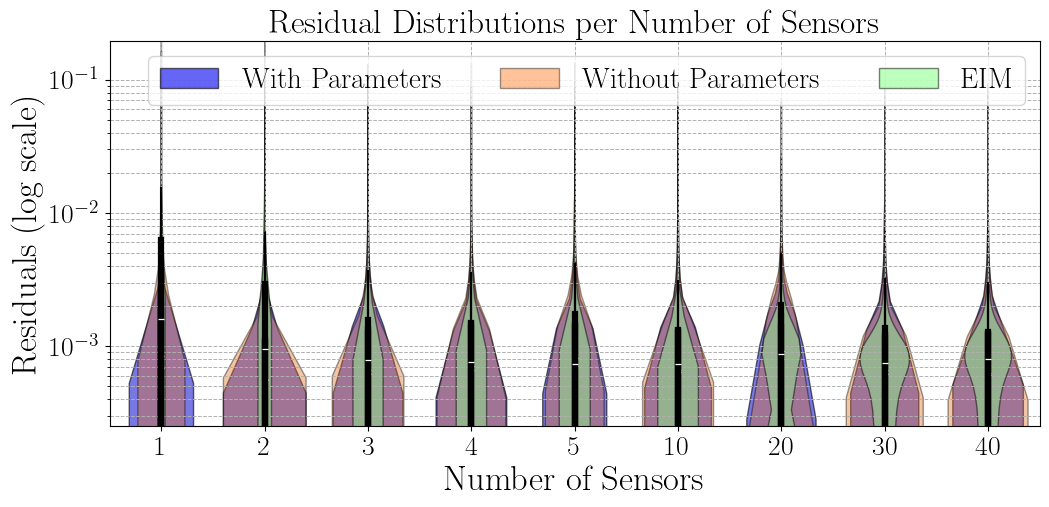

In [21]:
from matplotlib.patches import Patch


# Prepare data
residuals_with_per_condition = [errors['NumSensEIM_WithParam'].mean(axis=1)[i, :] for i in range(len(num_senss))]
residuals_without_per_condition = [errors['NumSensEIM_WithoutParam'].mean(axis=1)[i, :] for i in range(len(num_senss))]
residuals_eim = [errors['EIM'].mean(axis=1)[i, :] for i in range(len(num_senss))]

fig, ax = plt.subplots(figsize=(12, 5), sharey=True, sharex=True)

# Violin plots with edge colors for visibility
sns.violinplot(
    data=residuals_with_per_condition,
    color=cm.jet(0.1),
    alpha=0.6,
    linewidth=1,
    edgecolor='black',
    width=0.8,
    ax=ax
)

sns.violinplot(
    data=residuals_without_per_condition,
    color=cm.jet(0.8),
    alpha=0.4,
    linewidth=1,
    edgecolor='black',
    width=0.8,
    ax=ax
)

sns.violinplot(
    data=residuals_eim,
    color=cm.jet(0.5),
    alpha=0.5,
    linewidth=1,
    edgecolor='black',
    width=0.8,
    ax=ax
)

# Log scale on y-axis
ax.set_yscale('log')

# Set y-limits roughly to histogram range, adjust max_y as needed
max_y = max([arr.max() for arr in residuals_with_per_condition + residuals_without_per_condition if arr is not None and not np.all(np.isnan(arr))])
ax.set_ylim(2.5e-4, max_y*1.2)

# X-axis labels
ax.set_xticks(range(len(num_senss)))
ax.set_xticklabels([str(n) for n in num_senss], fontsize=22)
ax.set_xlabel('Number of Sensors', fontsize=25)

# Y-axis label
ax.set_ylabel('Residuals (log scale)', fontsize=25)

# Legend with matched colors
legend_elements = [
    Patch(facecolor=cm.jet(0.1), edgecolor='k', alpha=0.6, label='With Parameters'),
    Patch(facecolor=cm.jet(0.8), edgecolor='k', alpha=0.4, label='Without Parameters'),
    Patch(facecolor=cm.jet(0.5), edgecolor='k', alpha=0.5, label='EIM')
]
ax.legend(handles=legend_elements, fontsize=21, ncol=3, loc='upper right')

# Grid and title
ax.grid(True, which='both', linestyle='--', linewidth=0.7)
ax.set_title('Residual Distributions per Number of Sensors', fontsize=24)
ax.tick_params(axis='both', which='major', labelsize=20)

fig.savefig(path_res + f'violin_plot_sens{_stats}.pdf', bbox_inches='tight', dpi=300)